In [ ]:
install.packages(
  c("tidyverse", "janitor", "lubridate", "corrplot",
    "rpart", "rpart.plot", "randomForest", "knitr"),
  repos = "https://cloud.r-project.org"
)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘snakecase’




In [ ]:
library(tidyverse)
library(janitor)
library(lubridate)
library(corrplot)
library(rpart)
library(rpart.plot)
library(randomForest)
library(knitr)

set.seed(123)

cat("All required libraries loaded successfully!\n")

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘janitor’


The following objects are masked from ‘package:stats’:

    chisq.test, fisher.test


corrplot 0.95 loaded

randomForest 4.7-1.2

Type rfNews() to see new features/changes/bug fixes.


Attaching package: ‘randomForest’


The following object is masked from ‘package:dplyr’:

    combine


The following object is masked from ‘package:ggplot2’:

    margin




All required libraries loaded successfully!


In [ ]:
# load dataset
list.files("/content", recursive = TRUE)

[1] "Plant_1_Generation_Data.csv"             
[2] "Plant_1_Weather_Sensor_Data.csv"         
[3] "sample_data/anscombe.json"               
[4] "sample_data/california_housing_test.csv" 
[5] "sample_data/california_housing_train.csv"
[6] "sample_data/mnist_test.csv"              
[7] "sample_data/mnist_train_small.csv"       
[8] "sample_data/README.md"

In [ ]:
# Read the CSV files

base_path <- "/content"

generation_files <- list.files(
  base_path,
  pattern = "Plant_[12]_Generation_Data\\.csv$",
  recursive = TRUE,
  full.names = TRUE
)

weather_files <- list.files(
  base_path,
  pattern = "Plant_[12]_Weather_Sensor_Data\\.csv$",
  recursive = TRUE,
  full.names = TRUE
)

if (length(generation_files) == 0 || length(weather_files) == 0) {
  stop("CSV files not found. Check the filenames and upload location.")
}

# Read forcing DATE_TIME as character to avoid binding conflicts
generation_data <- purrr::map_dfr(
  generation_files,
  ~ readr::read_csv(.x, col_types = readr::cols(DATE_TIME = readr::col_character()), show_col_types = FALSE) |>
    mutate(source_file = basename(.x))
)

weather_data <- purrr::map_dfr(
  weather_files,
  ~ readr::read_csv(.x, col_types = readr::cols(DATE_TIME = readr::col_character()), show_col_types = FALSE) |>
    mutate(source_file = basename(.x))
)

# Clean names
generation_data <- generation_data |> clean_names()
weather_data <- weather_data |> clean_names()

# Parse date_time consistently using lubridate's flexible parsing helper
generation_data <- generation_data |>
  mutate(date_time = lubridate::ymd_hms(date_time, truncated = 3, quiet = TRUE) %>%
                      coalesce(lubridate::dmy_hm(date_time, quiet = TRUE)))

weather_data <- weather_data |>
  mutate(date_time = lubridate::ymd_hms(date_time, truncated = 3, quiet = TRUE) %>%
                      coalesce(lubridate::dmy_hm(date_time, quiet = TRUE)))

cat("Generation data:", nrow(generation_data), "rows and",
    ncol(generation_data), "columns\n")

cat("Weather data:", nrow(weather_data), "rows and",
    ncol(weather_data), "columns\n")

Generation data: 136476 rows and 8 columns
Weather data: 6441 rows and 7 columns


In [ ]:
# understand the dataset

glimpse(generation_data)
glimpse(weather_data)

names(generation_data)
names(weather_data)

Rows: 136,476
Columns: 8
$ date_time   <dttm> 2015-05-20 20:00:00, 2015-05-20 20:00:00, 2015-05-20 20:0…
$ plant_id    <dbl> 4135001, 4135001, 4135001, 4135001, 4135001, 4135001, 4135…
$ source_key  <chr> "1BY6WEcLGh8j5v7", "1IF53ai7Xc0U56Y", "3PZuoBAID5Wc2HD", "…
$ dc_power    <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0…
$ ac_power    <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0…
$ daily_yield <dbl> 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0…
$ total_yield <dbl> 6259559, 6183645, 6987759, 7602960, 7158964, 7206408, 7028…
$ source_file <chr> "Plant_1_Generation_Data.csv", "Plant_1_Generation_Data.cs…
Rows: 6,441
Columns: 7
$ date_time           <dttm> 2020-05-15 00:00:00, 2020-05-15 00:15:00, 2020-05…
$ plant_id            <dbl> 4135001, 4135001, 4135001, 4135001, 4135001, 41350…
$ source_key          <chr> "HmiyD2TTLFNqkNe", "HmiyD2TTLFNqkNe", "HmiyD2TTLFN…
$ ambient_temperature <dbl> 25.18432, 25.08459, 24.93575, 24.84613, 24.6

[1] "date_time"   "plant_id"    "source_key"  "dc_power"    "ac_power"   
[6] "daily_yield" "total_yield" "source_file"

[1] "date_time"           "plant_id"            "source_key"         
[4] "ambient_temperature" "module_temperature"  "irradiation"        
[7] "source_file"

In [ ]:
summary(generation_data)
summary(weather_data)

   date_time                      plant_id           source_key    
 Min.   :2001-06-20 20:00:00   Min.   :4135001   Length   :136476  
 1st Qu.:2016-05-20 20:09:30   1st Qu.:4135001   N.unique :    44  
 Median :2020-05-26 02:45:00   Median :4135001   N.blank  :     0  
 Mean   :2018-04-15 10:34:00   Mean   :4135497   Min.nchar:    15  
 3rd Qu.:2020-06-11 22:45:00   3rd Qu.:4136001   Max.nchar:    15  
 Max.   :2031-05-20 20:23:45   Max.   :4136001                     
    dc_power           ac_power         daily_yield       total_yield       
 Min.   :    0.00   Min.   :   0.000   Min.   :   0.00   Min.   :0.000e+00  
 1st Qu.:    0.00   1st Qu.:   0.000   1st Qu.:  28.32   1st Qu.:6.520e+06  
 Median :    6.05   Median :   3.507   Median :2834.80   Median :7.269e+06  
 Mean   : 1708.54   Mean   : 274.804   Mean   :3295.43   Mean   :3.304e+08  
 3rd Qu.: 1155.79   3rd Qu.: 532.673   3rd Qu.:5992.00   3rd Qu.:2.826e+08  
 Max.   :14471.12   Max.   :1410.950   Max.   :9873.00   Max. 

   date_time                      plant_id           source_key  
 Min.   :2020-05-15 00:00:00   Min.   :4135001   Length   :6441  
 1st Qu.:2020-05-23 17:15:00   1st Qu.:4135001   N.unique :   2  
 Median :2020-06-01 05:00:00   Median :4136001   N.blank  :   0  
 Mean   :2020-06-01 02:56:23   Mean   :4135507   Min.nchar:  15  
 3rd Qu.:2020-06-09 14:30:00   3rd Qu.:4136001   Max.nchar:  15  
 Max.   :2020-06-17 23:45:00   Max.   :4136001                   
 ambient_temperature module_temperature  irradiation         source_file  
 Min.   :20.40       Min.   :18.14      Min.   :0.00000   Length   :6441  
 1st Qu.:23.66       1st Qu.:22.43      1st Qu.:0.00000   N.unique :   2  
 Median :25.95       Median :26.39      Median :0.02228   N.blank  :   0  
 Mean   :26.82       Mean   :31.94      Mean   :0.23055   Min.nchar:  31  
 3rd Qu.:29.36       3rd Qu.:40.82      3rd Qu.:0.44334   Max.nchar:  31  
 Max.   :39.18       Max.   :66.64      Max.   :1.22165                   

In [ ]:
head(generation_data, 10)
head(weather_data, 10)

date_time,plant_id,source_key,dc_power,ac_power,daily_yield,total_yield,source_file
<dttm>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
2015-05-20 20:00:00,4135001,1BY6WEcLGh8j5v7,0,0,0,6259559,Plant_1_Generation_Data.csv
2015-05-20 20:00:00,4135001,1IF53ai7Xc0U56Y,0,0,0,6183645,Plant_1_Generation_Data.csv
2015-05-20 20:00:00,4135001,3PZuoBAID5Wc2HD,0,0,0,6987759,Plant_1_Generation_Data.csv
2015-05-20 20:00:00,4135001,7JYdWkrLSPkdwr4,0,0,0,7602960,Plant_1_Generation_Data.csv
2015-05-20 20:00:00,4135001,McdE0feGgRqW7Ca,0,0,0,7158964,Plant_1_Generation_Data.csv
2015-05-20 20:00:00,4135001,VHMLBKoKgIrUVDU,0,0,0,7206408,Plant_1_Generation_Data.csv
2015-05-20 20:00:00,4135001,WRmjgnKYAwPKWDb,0,0,0,7028673,Plant_1_Generation_Data.csv
2015-05-20 20:00:00,4135001,ZnxXDlPa8U1GXgE,0,0,0,6522172,Plant_1_Generation_Data.csv
2015-05-20 20:00:00,4135001,ZoEaEvLYb1n2sOq,0,0,0,7098099,Plant_1_Generation_Data.csv


date_time,plant_id,source_key,ambient_temperature,module_temperature,irradiation,source_file
<dttm>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<chr>
2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.18432,22.85751,0,Plant_1_Weather_Sensor_Data.csv
2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.08459,22.76167,0,Plant_1_Weather_Sensor_Data.csv
2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.93575,22.59231,0,Plant_1_Weather_Sensor_Data.csv
2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.84613,22.36085,0,Plant_1_Weather_Sensor_Data.csv
2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.62153,22.16542,0,Plant_1_Weather_Sensor_Data.csv
2020-05-15 01:15:00,4135001,HmiyD2TTLFNqkNe,24.53609,21.96857,0,Plant_1_Weather_Sensor_Data.csv
2020-05-15 01:30:00,4135001,HmiyD2TTLFNqkNe,24.63867,22.35293,0,Plant_1_Weather_Sensor_Data.csv
2020-05-15 01:45:00,4135001,HmiyD2TTLFNqkNe,24.87302,23.16092,0,Plant_1_Weather_Sensor_Data.csv
2020-05-15 02:00:00,4135001,HmiyD2TTLFNqkNe,24.93693,23.02611,0,Plant_1_Weather_Sensor_Data.csv


In [ ]:
# Clean and preprocess the data

# Missing values in each dataset
colSums(is.na(generation_data))
colSums(is.na(weather_data))

# Count duplicate rows
sum(duplicated(generation_data))
sum(duplicated(weather_data))

# Check column data types
sapply(generation_data, class)
sapply(weather_data, class)

date_time    plant_id  source_key    dc_power    ac_power daily_yield 
          0           0           0           0           0           0 
total_yield source_file 
          0           0

date_time            plant_id          source_key ambient_temperature 
                  0                   0                   0                   0 
 module_temperature         irradiation         source_file 
                  0                   0                   0

[1] 0

[1] 0

$date_time
[1] "POSIXct" "POSIXt" 

$plant_id
[1] "numeric"

$source_key
[1] "character"

$dc_power
[1] "numeric"

$ac_power
[1] "numeric"

$daily_yield
[1] "numeric"

$total_yield
[1] "numeric"

$source_file
[1] "character"

$date_time
[1] "POSIXct" "POSIXt" 

$plant_id
[1] "numeric"

$source_key
[1] "character"

$ambient_temperature
[1] "numeric"

$module_temperature
[1] "numeric"

$irradiation
[1] "numeric"

$source_file
[1] "character"

In [ ]:
# 1. Reload raw clean character datasets to avoid conflict with partially modified dates
generation_data <- purrr::map_dfr(
  generation_files,
  ~ readr::read_csv(.x, col_types = readr::cols(DATE_TIME = readr::col_character()), show_col_types = FALSE) |>
    mutate(source_file = basename(.x))
) |> janitor::clean_names() |> distinct()

weather_data <- purrr::map_dfr(
  weather_files,
  ~ readr::read_csv(.x, col_types = readr::cols(DATE_TIME = readr::col_character()), show_col_types = FALSE) |>
    mutate(source_file = basename(.x))
) |> janitor::clean_names() |> distinct()

# 2. Convert date/time strings cleanly
generation_data <- generation_data |>
  mutate(
    date_time = parse_date_time(
      date_time,
      orders = c("ymd HMS", "ymd HM", "dmy HMS", "dmy HM")
    )
  )

weather_data <- weather_data |>
  mutate(
    date_time = parse_date_time(
      date_time,
      orders = c("ymd HMS", "ymd HM", "dmy HMS", "dmy HM")
    )
  )

# 3. Check whether any timestamps failed to parse
cat("Unparsed Generation timestamps:", sum(is.na(generation_data$date_time)), "\n")
cat("Unparsed Weather timestamps:", sum(is.na(weather_data$date_time)), "\n")

Unparsed Generation timestamps: 0 
Unparsed Weather timestamps: 0 


In [ ]:
# Let's reload the raw character column to inspect what failed to parse
# We will inspect a sample of rows where the parsed date_time resulted in NA
raw_gen <- purrr::map_dfr(
  generation_files,
  ~ readr::read_csv(.x, col_types = readr::cols(DATE_TIME = readr::col_character()), show_col_types = FALSE) |>
    mutate(source_file = basename(.x))
) |> janitor::clean_names() |> distinct()

failed_parses_gen <- raw_gen$date_time[is.na(generation_data$date_time)]
cat("Sample of failed generation timestamps:", head(failed_parses_gen, 10), "\n")

raw_wea <- purrr::map_dfr(
  weather_files,
  ~ readr::read_csv(.x, col_types = readr::cols(DATE_TIME = readr::col_character()), show_col_types = FALSE) |>
    mutate(source_file = basename(.x))
) |> janitor::clean_names() |> distinct()

failed_parses_wea <- raw_wea$date_time[is.na(weather_data$date_time)]
cat("Sample of failed weather timestamps:", head(failed_parses_wea, 10), "\n")

Sample of failed generation timestamps: 2020-05-15 00:00:00 2020-05-15 00:00:00 2020-05-15 00:00:00 2020-05-15 00:00:00 2020-05-15 00:00:00 2020-05-15 00:00:00 2020-05-15 00:00:00 2020-05-15 00:00:00 2020-05-15 00:00:00 2020-05-15 00:00:00 
Sample of failed weather timestamps: 2020-05-15 00:00:00 2020-05-17 00:00:00 2020-05-18 00:00:00 2020-05-19 00:00:00 2020-05-20 00:00:00 2020-05-21 00:00:00 2020-05-22 00:00:00 2020-05-23 00:00:00 2020-05-24 00:00:00 2020-05-25 00:00:00 


In [ ]:
# Remove rows with missing timestamps or essential measurements
generation_data <- generation_data |>
  filter(
    !is.na(date_time),
    !is.na(ac_power),
    !is.na(plant_id)
  )

weather_data <- weather_data |>
  filter(
    !is.na(date_time),
    !is.na(plant_id)
  )

# Check missing values in the main numeric variables
generation_data |>
  summarise(
    missing_ac_power = sum(is.na(ac_power)),
    missing_daily_yield = sum(is.na(daily_yield))
  )

weather_data |>
  summarise(
    missing_ambient_temp = sum(is.na(ambient_temperature)),
    missing_module_temp = sum(is.na(module_temperature)),
    missing_irradiation = sum(is.na(irradiation))
  )

missing_ac_power,missing_daily_yield
<int>,<int>
0,0


missing_ambient_temp,missing_module_temp,missing_irradiation
<int>,<int>,<int>
0,0,0


In [ ]:
# EDA

generation_data |>
  summarise(
    mean_ac_power = mean(ac_power, na.rm = TRUE),
    median_ac_power = median(ac_power, na.rm = TRUE),
    sd_ac_power = sd(ac_power, na.rm = TRUE),
    min_ac_power = min(ac_power, na.rm = TRUE),
    max_ac_power = max(ac_power, na.rm = TRUE)
  )

weather_data |>
  summarise(
    mean_irradiation = mean(irradiation, na.rm = TRUE),
    mean_ambient_temp = mean(ambient_temperature, na.rm = TRUE),
    mean_module_temp = mean(module_temperature, na.rm = TRUE)
  )

mean_ac_power,median_ac_power,sd_ac_power,min_ac_power,max_ac_power
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
274.8035,3.506905,380.1826,0,1410.95


mean_irradiation,mean_ambient_temp,mean_module_temp
<dbl>,<dbl>,<dbl>
0.2305513,26.81567,31.94176


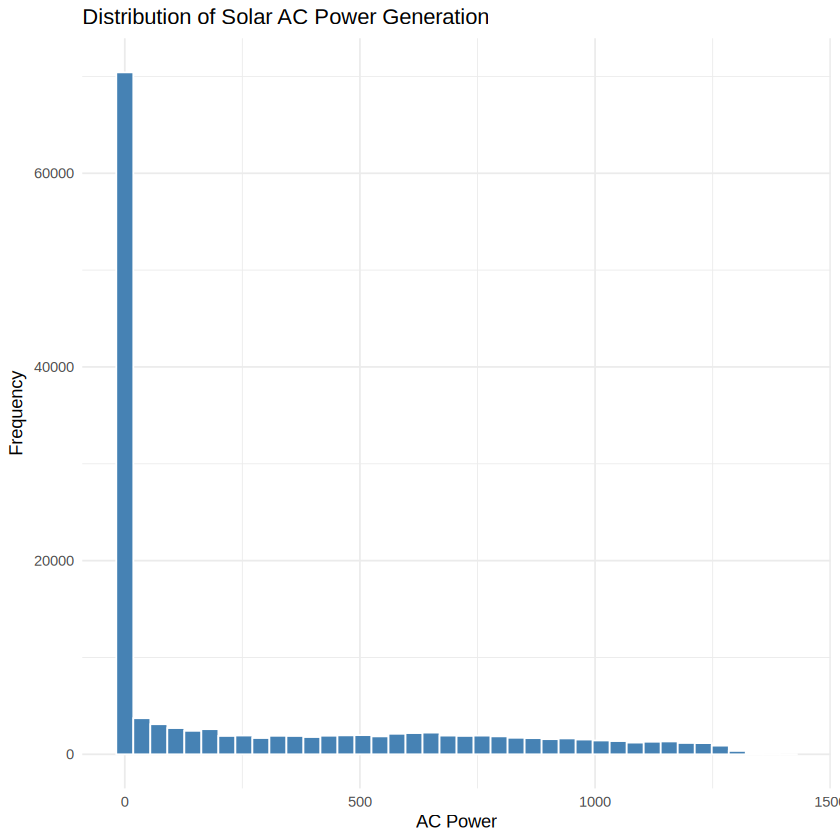

In [ ]:
ggplot(generation_data, aes(x = ac_power)) +
  geom_histogram(bins = 40, fill = "steelblue", color = "white") +
  labs(
    title = "Distribution of Solar AC Power Generation",
    x = "AC Power",
    y = "Frequency"
  ) +
  theme_minimal()

# Interpretation: This graph shows how frequently different power-output levels occur.
#Many observations may be close to zero because solar panels produce little or no power at night.

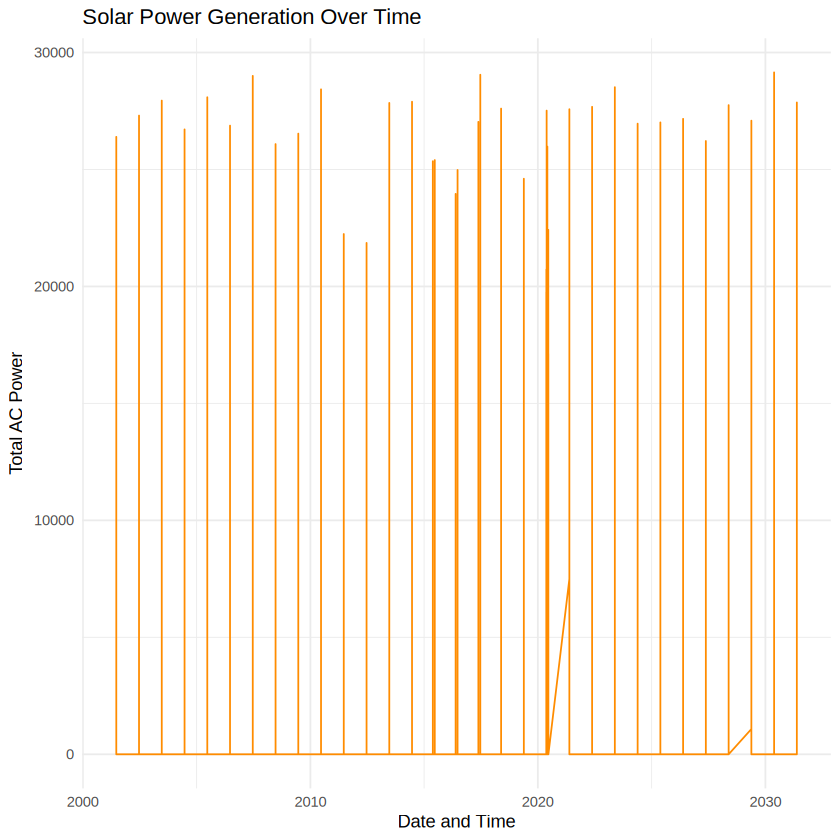

In [ ]:
generation_data |>
  group_by(date_time) |>
  summarise(
    total_ac_power = sum(ac_power, na.rm = TRUE),
    .groups = "drop"
  ) |>
  ggplot(aes(x = date_time, y = total_ac_power)) +
  geom_line(color = "darkorange") +
  labs(
    title = "Solar Power Generation Over Time",
    x = "Date and Time",
    y = "Total AC Power"
  ) +
  theme_minimal()

# Interpretation: Look for daily fluctuations, repeated generation patterns, and periods of unusually low or high output.

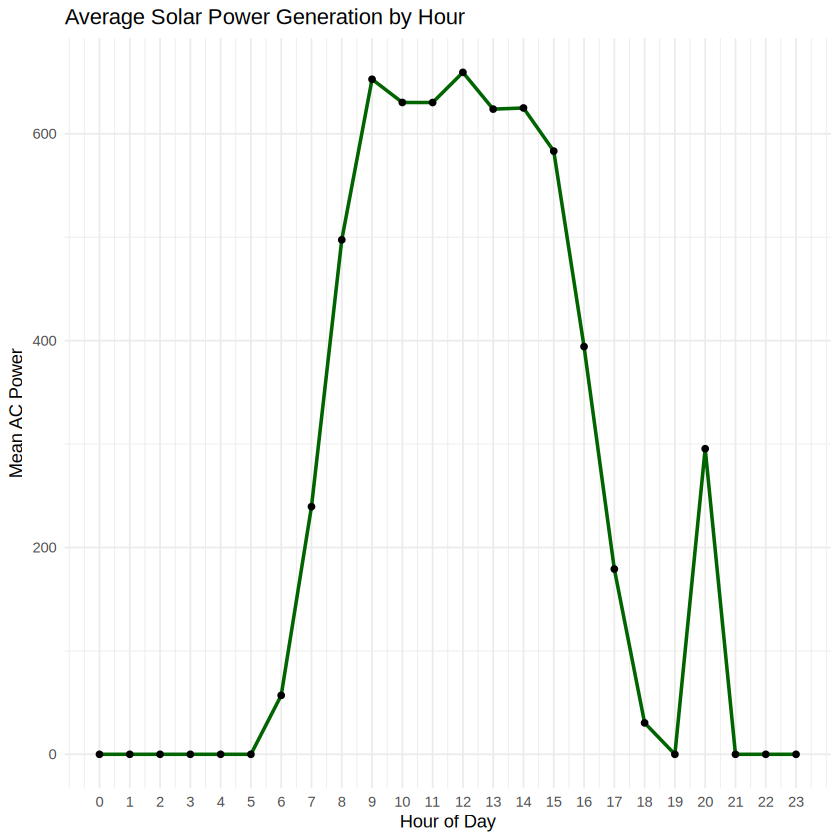

In [ ]:
generation_data |>
  mutate(hour = hour(date_time)) |>
  group_by(hour) |>
  summarise(
    mean_ac_power = mean(ac_power, na.rm = TRUE),
    .groups = "drop"
  ) |>
  ggplot(aes(x = hour, y = mean_ac_power)) +
  geom_line(color = "darkgreen", linewidth = 1) +
  geom_point() +
  scale_x_continuous(breaks = 0:23) +
  labs(
    title = "Average Solar Power Generation by Hour",
    x = "Hour of Day",
    y = "Mean AC Power"
  ) +
  theme_minimal()

# Interpretation: This helps reveal when generation typically begins, peaks, and falls during the day.

In [ ]:
# Combine generation and weather data

weather_summary <- weather_data |>
  group_by(date_time, plant_id) |>
  summarise(
    ambient_temperature = mean(ambient_temperature, na.rm = TRUE),
    module_temperature = mean(module_temperature, na.rm = TRUE),
    irradiation = mean(irradiation, na.rm = TRUE),
    .groups = "drop"
  )

# Convert NaN values from all-missing groups to NA
weather_summary <- weather_summary |>
  mutate(
    across(
      c(ambient_temperature, module_temperature, irradiation),
      ~ ifelse(is.nan(.x), NA_real_, .x)
    )
  )

solar_data <- generation_data |>
  select(
    date_time, plant_id, ac_power, daily_yield, total_yield
  ) |>
  left_join(
    weather_summary,
    by = c("date_time", "plant_id")
  ) |>
  arrange(date_time)

dim(solar_data)
head(solar_data)

[1] 136476      8

date_time,plant_id,ac_power,daily_yield,total_yield,ambient_temperature,module_temperature,irradiation
<dttm>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2001-06-20 20:00:00,4135001,0,829.000,6377931,NA,NA,NA
2001-06-20 20:00:00,4135001,0,0.000,6311432,NA,NA,NA
2001-06-20 20:00:00,4135001,0,0.000,7115304,NA,NA,NA
2001-06-20 20:00:00,4135001,0,730.375,7727821,NA,NA,NA
2001-06-20 20:00:00,4135001,0,0.000,7286760,NA,NA,NA
2001-06-20 20:00:00,4135001,0,759.500,7334405,NA,NA,NA


In [ ]:
solar_data |>
  summarise(
    total_rows = n(),
    missing_irradiation = sum(is.na(irradiation)),
    missing_ambient_temperature = sum(is.na(ambient_temperature)),
    missing_module_temperature = sum(is.na(module_temperature))
  )

total_rows,missing_irradiation,missing_ambient_temperature,missing_module_temperature
<int>,<int>,<int>,<int>
136476,68756,68756,68756


`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 68756 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 68756 rows containing missing values or values outside the scale range
(`geom_point()`).”


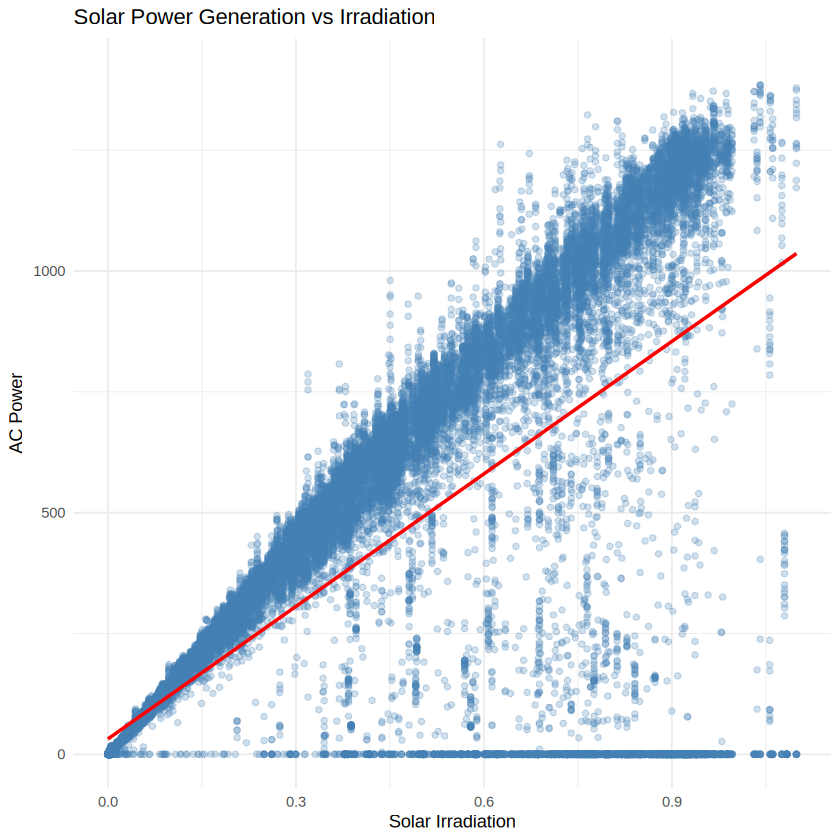

In [ ]:
ggplot(
  solar_data,
  aes(x = irradiation, y = ac_power)
) +
  geom_point(alpha = 0.25, color = "steelblue") +
  geom_smooth(method = "lm", se = TRUE, color = "red") +
  labs(
    title = "Solar Power Generation vs Irradiation",
    x = "Solar Irradiation",
    y = "AC Power"
  ) +
  theme_minimal()

# Interpretation: Check whether higher irradiation is associated with higher AC power generation.

`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 68756 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 68756 rows containing missing values or values outside the scale range
(`geom_point()`).”


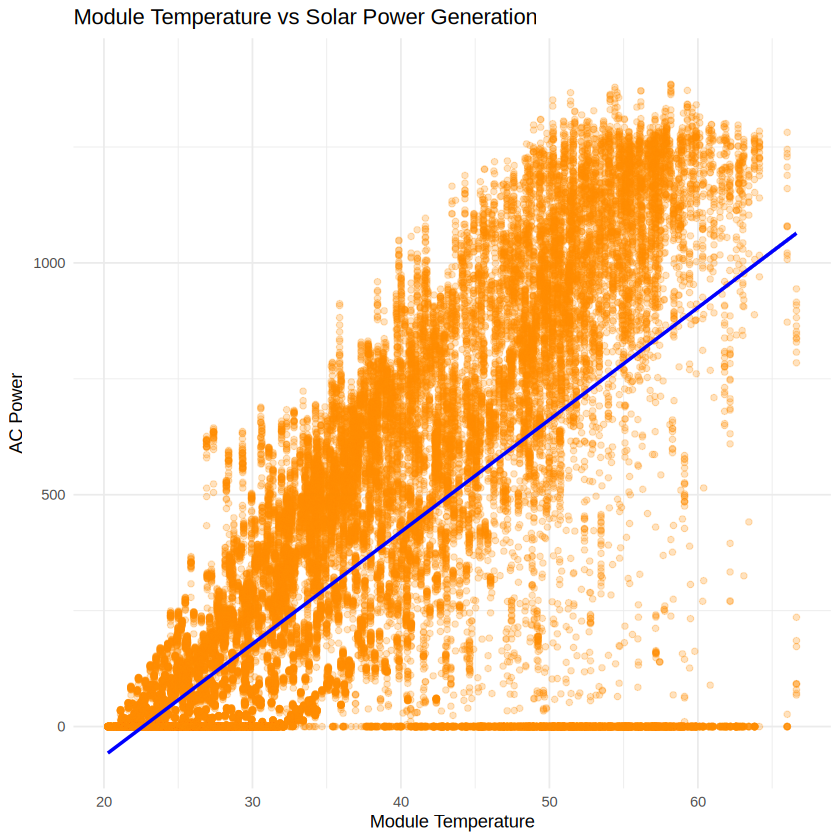

In [ ]:
ggplot(
  solar_data,
  aes(x = module_temperature, y = ac_power)
) +
  geom_point(alpha = 0.25, color = "darkorange") +
  geom_smooth(method = "lm", se = TRUE, color = "blue") +
  labs(
    title = "Module Temperature vs Solar Power Generation",
    x = "Module Temperature",
    y = "AC Power"
  ) +
  theme_minimal()

# Interpretation: This explores the association between module temperature and power output. The relationship may also depend on irradiation and time of day.

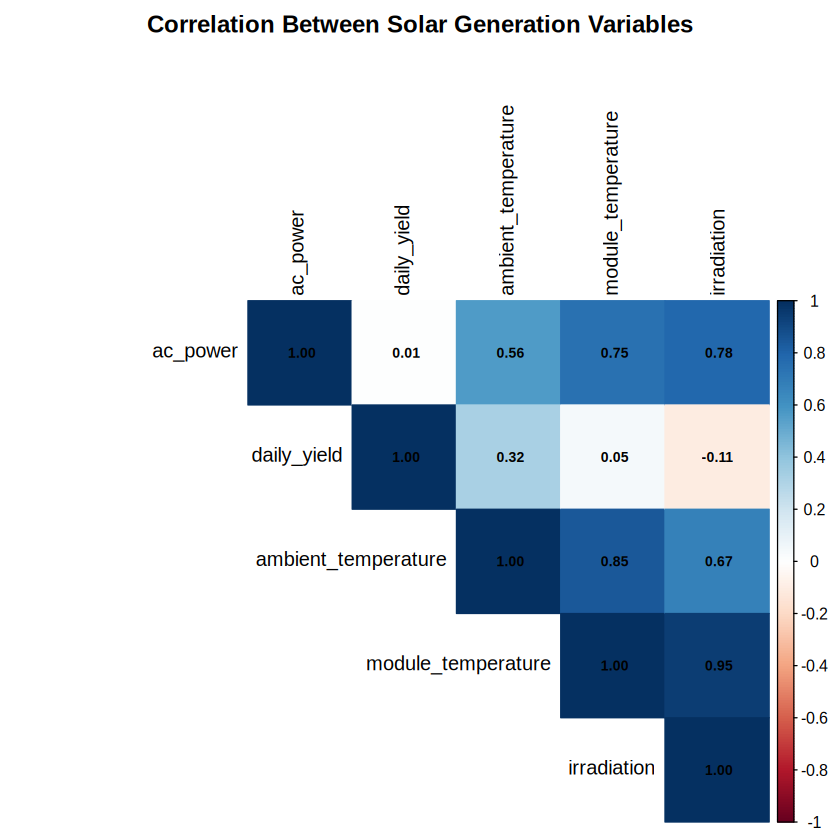

In [ ]:
correlation_data <- solar_data |>
  select(
    ac_power,
    daily_yield,
    ambient_temperature,
    module_temperature,
    irradiation
  ) |>
  drop_na()

correlation_matrix <- cor(correlation_data)

corrplot(
  correlation_matrix,
  method = "color",
  type = "upper",
  addCoef.col = "black",
  tl.col = "black",
  number.cex = 0.7,
  title = "Correlation Between Solar Generation Variables",
  mar = c(0, 0, 2, 0)
)

# Interpretation: Correlation shows the strength and direction of linear associations. It does not establish causation

In [ ]:
# Feature engineering

model_data <- solar_data |>
  mutate(
    hour = hour(date_time),
    day = day(date_time),
    month = month(date_time),
    day_of_week = wday(date_time, label = TRUE),
    plant_id = as.factor(plant_id)
  ) |>
  select(
    date_time,
    ac_power,
    irradiation,
    ambient_temperature,
    module_temperature,
    hour,
    day,
    month,
    day_of_week,
    plant_id
  ) |>
  drop_na() |>
  arrange(date_time)

dim(model_data)
summary(model_data)

[1] 67720    10

   date_time                      ac_power       irradiation     
 Min.   :2020-05-15 00:00:00   Min.   :   0.0   Min.   :0.00000  
 1st Qu.:2020-05-23 20:45:00   1st Qu.:   0.0   1st Qu.:0.00000  
 Median :2020-06-01 22:45:00   Median :   0.0   Median :0.01837  
 Mean   :2020-06-01 10:39:07   Mean   : 241.2   Mean   :0.22913  
 3rd Qu.:2020-06-09 23:30:00   3rd Qu.: 438.0   3rd Qu.:0.43067  
 Max.   :2020-06-17 23:45:00   Max.   :1385.4   Max.   :1.09877  
                                                                 
 ambient_temperature module_temperature      hour            day       
 Min.   :20.94       Min.   :20.27      Min.   : 0.00   Min.   : 1.00  
 1st Qu.:24.57       1st Qu.:23.68      1st Qu.: 6.00   1st Qu.: 9.00  
 Median :26.90       Median :27.42      Median :12.00   Median :16.00  
 Mean   :27.99       Mean   :32.60      Mean   :11.53   Mean   :15.53  
 3rd Qu.:30.91       3rd Qu.:40.02      3rd Qu.:18.00   3rd Qu.:22.00  
 Max.   :39.18       Max.   :66.64      

In [ ]:
# Split training and testing data

if (nrow(model_data) < 20) {
  stop("Too few complete observations. Check the data merge and missing values.")
}

split_index <- floor(0.8 * nrow(model_data))

train_data <- model_data[1:split_index, ]
test_data <- model_data[(split_index + 1):nrow(model_data), ]

cat("Training rows:", nrow(train_data), "\n")
cat("Testing rows:", nrow(test_data), "\n")

cat(
  "Training period:",
  as.character(min(train_data$date_time)), "to",
  as.character(max(train_data$date_time)), "\n"
)

cat(
  "Testing period:",
  as.character(min(test_data$date_time)), "to",
  as.character(max(test_data$date_time)), "\n"
)

Training rows: 54176 
Testing rows: 13544 
Training period: 2020-05-15 to 2020-06-11 14:00:00 
Testing period: 2020-06-11 14:00:00 to 2020-06-17 23:45:00 


In [ ]:
# Build three regression models

model_formula <- ac_power ~
  irradiation +
  ambient_temperature +
  module_temperature +
  hour +
  day +
  month +
  day_of_week +
  plant_id

linear_model <- lm(
  model_formula,
  data = train_data
)

summary(linear_model)

pred_linear <- predict(
  linear_model,
  newdata = test_data
)


Call:
lm(formula = model_formula, data = train_data)

Residuals:
     Min       1Q   Median       3Q      Max 
-1028.97   -36.63    -8.77   102.05   685.00 

Coefficients:
                     Estimate Std. Error t value Pr(>|t|)    
(Intercept)         -307.7961    58.2820  -5.281 1.29e-07 ***
irradiation          990.7847    16.3340  60.658  < 2e-16 ***
ambient_temperature   17.1740     0.8254  20.806  < 2e-16 ***
module_temperature    -6.5695     0.6268 -10.482  < 2e-16 ***
hour                  -1.8238     0.1775 -10.278  < 2e-16 ***
day                    0.3224     0.2418   1.333  0.18251    
month                 12.7992     4.6122   2.775  0.00552 ** 
day_of_week.L        -14.1318     2.6788  -5.275 1.33e-07 ***
day_of_week.Q         -0.2564     2.7699  -0.093  0.92624    
day_of_week.C          7.7672     2.7201   2.856  0.00430 ** 
day_of_week^4        -20.7780     2.7308  -7.609 2.81e-14 ***
day_of_week^5          7.7389     2.7318   2.833  0.00462 ** 
day_of_week^6        

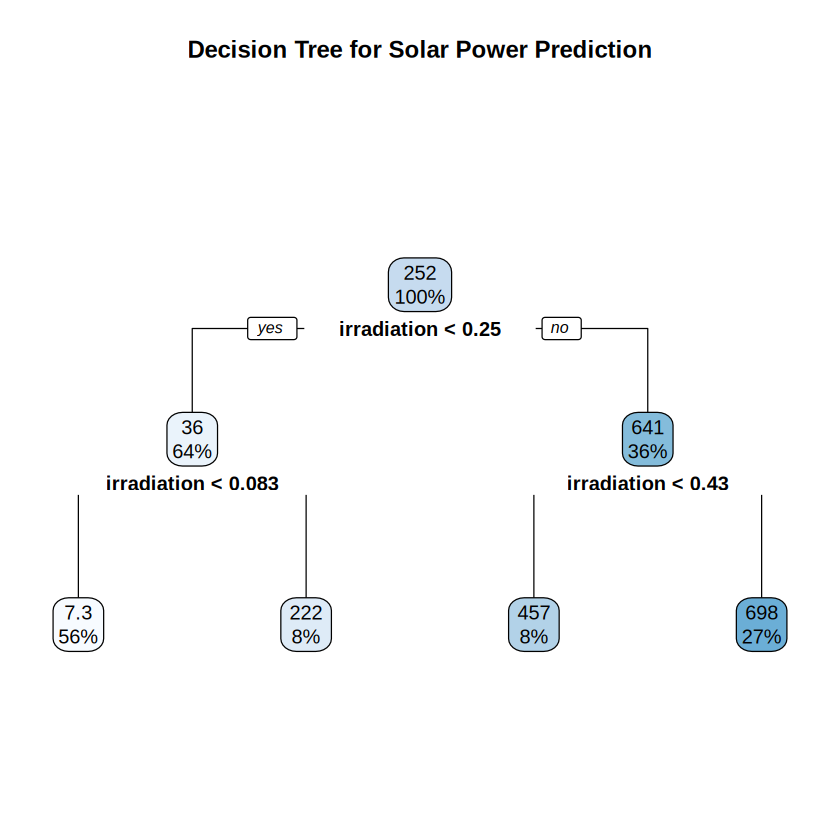

In [ ]:
# Model 2: Decision Tree Regression

tree_model <- rpart(
  model_formula,
  data = train_data,
  method = "anova",
  control = rpart.control(
    maxdepth = 8,
    minsplit = 20
  )
)

rpart.plot(
  tree_model,
  main = "Decision Tree for Solar Power Prediction"
)

pred_tree <- predict(
  tree_model,
  newdata = test_data
)

In [ ]:
# Model 3: Random Forest Regression

set.seed(123)

rf_model <- randomForest(
  model_formula,
  data = train_data,
  ntree = 200,
  importance = TRUE
)

print(rf_model)

pred_rf <- predict(
  rf_model,
  newdata = test_data
)


Call:
 randomForest(formula = model_formula, data = train_data, ntree = 200,      importance = TRUE) 
               Type of random forest: regression
                     Number of trees: 200
No. of variables tried at each split: 2

          Mean of squared residuals: 46822.53
                    % Var explained: 67.31


In [ ]:
# Evaluate the models
#We'll use three standard regression metrics:
#- MAE: average absolute prediction error.
#- RMSE: penalizes larger prediction errors more heavily.
#- R²: measures how much variation the model explains relative to predicting the test-set mean.

calculate_metrics <- function(actual, predicted, model_name) {
  data.frame(
    Model = model_name,
    MAE = mean(abs(actual - predicted)),
    RMSE = sqrt(mean((actual - predicted)^2)),
    R2 = 1 - sum((actual - predicted)^2) /
      sum((actual - mean(actual))^2)
  )
}

results <- bind_rows(
  calculate_metrics(test_data$ac_power, pred_linear, "Linear Regression"),
  calculate_metrics(test_data$ac_power, pred_tree, "Decision Tree"),
  calculate_metrics(test_data$ac_power, pred_rf, "Random Forest")
)

results <- results |>
  arrange(RMSE)

print(results)

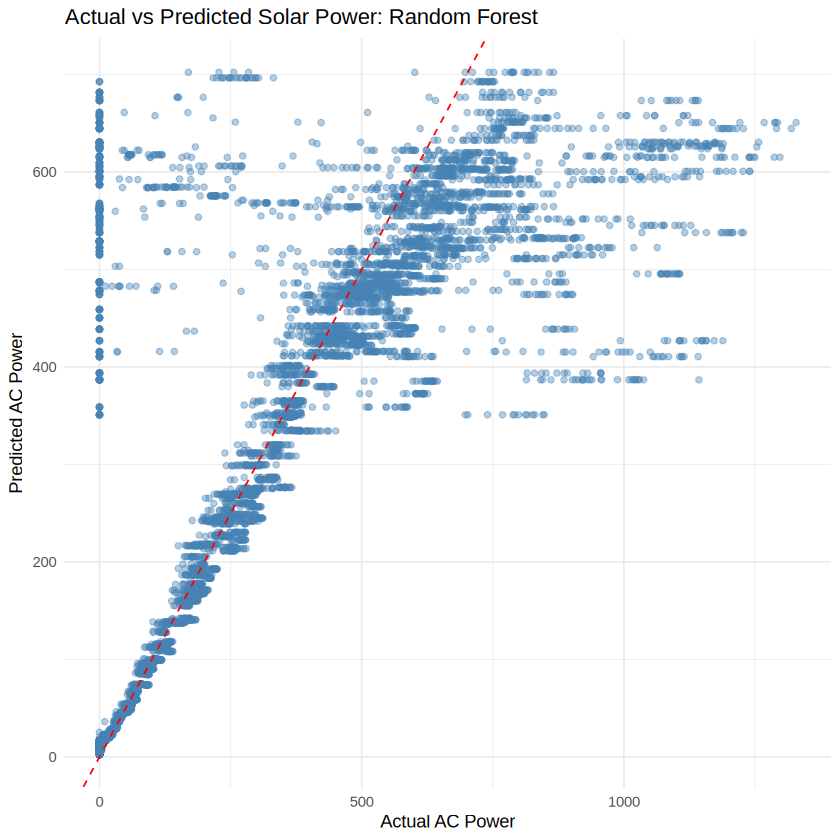

In [ ]:
prediction_results <- data.frame(
  actual = test_data$ac_power,
  linear_regression = pred_linear,
  decision_tree = pred_tree,
  random_forest = pred_rf
)

ggplot(
  prediction_results,
  aes(x = actual, y = random_forest)
) +
  geom_point(alpha = 0.4, color = "steelblue") +
  geom_abline(
    slope = 1,
    intercept = 0,
    color = "red",
    linetype = "dashed"
  ) +
  labs(
    title = "Actual vs Predicted Solar Power: Random Forest",
    x = "Actual AC Power",
    y = "Predicted AC Power"
  ) +
  theme_minimal()

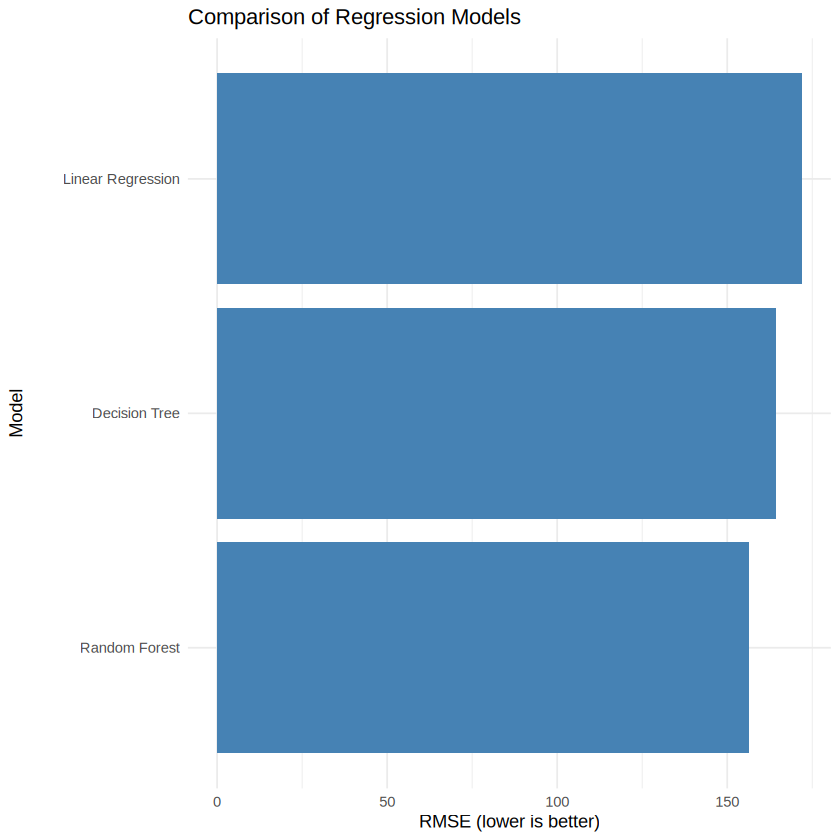

In [ ]:
# Recalculate results to ensure the object exists in this environment session
calculate_metrics <- function(actual, predicted, model_name) {
  data.frame(
    Model = model_name,
    MAE = mean(abs(actual - predicted)),
    RMSE = sqrt(mean((actual - predicted)^2)),
    R2 = 1 - sum((actual - predicted)^2) /
      sum((actual - mean(actual))^2)
  )
}

results <- bind_rows(
  calculate_metrics(test_data$ac_power, pred_linear, "Linear Regression"),
  calculate_metrics(test_data$ac_power, pred_tree, "Decision Tree"),
  calculate_metrics(test_data$ac_power, pred_rf, "Random Forest")
) |> arrange(RMSE)

ggplot(
  results,
  aes(x = reorder(Model, RMSE), y = RMSE)
) +
  geom_col(fill = "steelblue") +
  coord_flip() +
  labs(
    title = "Comparison of Regression Models",
    x = "Model",
    y = "RMSE (lower is better)"
  ) +
  theme_minimal()

,%IncMSE,IncNodePurity
irradiation,25.430063,2.389059e+09
ambient_temperature,14.846909,6.685550e+08
module_temperature,15.582162,1.477329e+09
hour,12.841559,6.459257e+08
day,29.572206,8.948902e+07
month,12.037949,2.459668e+07
day_of_week,31.111639,4.564523e+07
plant_id,1.009756,9.967795e+03


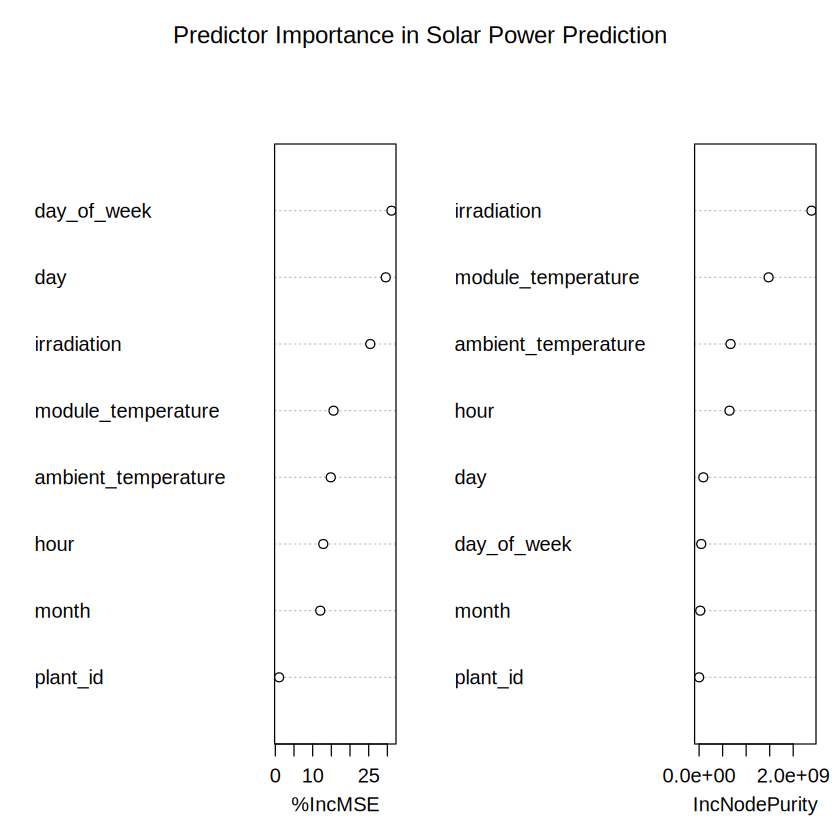

In [ ]:
importance(rf_model)

varImpPlot(
  rf_model,
  main = "Predictor Importance in Solar Power Prediction"
)

In [ ]:
write.csv(
  solar_data,
  "/content/cleaned_solar_data.csv",
  row.names = FALSE
)

write.csv(
  results,
  "/content/model_evaluation_results.csv",
  row.names = FALSE
)

write.csv(
  prediction_results,
  "/content/solar_power_predictions.csv",
  row.names = FALSE
)

write.csv(
  as.data.frame(importance(rf_model)),
  "/content/random_forest_importance.csv"
)

cat("Files saved successfully!\n")
list.files("/content", pattern = "\\.csv$")

Files saved successfully!


[1] "cleaned_solar_data.csv"          "model_evaluation_results.csv"   
[3] "Plant_1_Generation_Data.csv"     "Plant_1_Weather_Sensor_Data.csv"
[5] "Plant_2_Generation_Data.csv"     "Plant_2_Weather_Sensor_Data.csv"
[7] "random_forest_importance.csv"    "solar_power_predictions.csv"

In [ ]:
cat("SOLAR ENERGY GENERATION ANALYSIS AND PREDICTION\n")
cat("===============================================\n\n")

cat("Generation dataset dimensions:\n")
print(dim(generation_data))

cat("\nWeather dataset dimensions:\n")
print(dim(weather_data))

cat("\nMerged dataset dimensions:\n")
print(dim(solar_data))

cat("\nModel dataset dimensions:\n")
print(dim(model_data))

cat("\nModel evaluation results:\n")
print(results)

cat("\nBest model by RMSE:\n")
print(results[which.min(results$RMSE), ])

SOLAR ENERGY GENERATION ANALYSIS AND PREDICTION

Generation dataset dimensions:
[1] 136476      8

Weather dataset dimensions:
[1] 6441    7

Merged dataset dimensions:
[1] 136476      8

Model dataset dimensions:
[1] 67720    10

Model evaluation results:
              Model      MAE     RMSE        R2
1     Random Forest 66.33454 156.4214 0.6950880
2     Decision Tree 75.93786 164.4387 0.6630308
3 Linear Regression 98.19284 171.8835 0.6318280

Best model by RMSE:
          Model      MAE     RMSE       R2
1 Random Forest 66.33454 156.4214 0.695088
